# FinSight AI - Notebook 2: Domain-Adaptive Continued Pretraining (DAPT)

**Goal:** Train 2 open-weight LLMs on the financial corpus from Notebook 1 using QLoRA, compare their held-out financial-corpus perplexity, and save the selected adapter as **Checkpoint 1**.

Flow: `DAPT corpus → QLoRA continued pretraining → validation loss/perplexity → model comparison → Checkpoint 1`.

**Do not load the evaluation datasets in this notebook.**

## 1. Install dependencies

Use a Colab GPU runtime. A T4 can work with conservative settings; more VRAM will make the experiment easier.

In [1]:
!pip -q install -U unsloth transformers datasets accelerate peft bitsandbytes sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.2/81.2 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 119.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import gc
import json
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

assert torch.cuda.is_available(), 'Enable a GPU runtime in Colab.'
print('GPU:', torch.cuda.get_device_name(0))
print('VRAM GB:', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

TRAIN_FILE = Path('/content/Domain_Specific_Traning_processed_data/dapt_train.jsonl')
VAL_FILE = Path('/content/Domain_Specific_Traning_processed_data/dapt_validation.jsonl')
WORK_DIR = Path('/content/finsight_dapt')
MODEL_DIR = WORK_DIR / 'models'
RESULTS_DIR = WORK_DIR / 'results'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert TRAIN_FILE.exists(), f'Not found: {TRAIN_FILE}'
assert VAL_FILE.exists(), f'Not found: {VAL_FILE}'

GPU: Tesla T4
VRAM GB: 14.56


## 2. Load the corpus

In [3]:
from datasets import load_dataset

train_raw = load_dataset('json', data_files=str(TRAIN_FILE), split='train')
val_raw = load_dataset('json', data_files=str(VAL_FILE), split='train')

print('Train documents:', len(train_raw))
print('Validation documents:', len(val_raw))
print('Columns:', train_raw.column_names)
print('\nSample:')
print(train_raw[0]['text'][:1000])

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Train documents: 10
Validation documents: 2
Columns: ['document_id', 'filename', 'company', 'document_type', 'text']

Sample:
Synthetic training document - FinSight AI Financial Domain Corpus
Page 1
FinoraPay Technologies, Inc.
Annual Report and Form 10-K
Ticker: FNPP
Industry: Payments Technology
Fiscal year: 2025
Reporting currency: USD billions unless otherwise stated
FICTIONAL SYNTHETIC DOCUMENT
This document is entirely fictional and was created for the FinSight AI portfolio project. Company names, financial figures, transactions, management
statements, and market data are synthetic. It is not an SEC filing, investment recommendation, or representation of any real company.

Synthetic training document - FinSight AI Financial Domain Corpus
Page 2
1. Company Overview
FinoraPay Technologies, Inc. is a fictional payments technology company serving institutional and commercial customers
through an integrated set of financial products and digital services. During 2025, management focuse

## 3. Candidate models

vLLM is **not** the model source. The base models come from Hugging Face; vLLM will be used later for serving/inference benchmarking.

For a practical Colab experiment we use two candidates.

In [4]:
MODEL_CANDIDATES = {
    "qwen3_8b": "Qwen/Qwen3-8B",
    "mistral_7b": "mistralai/Mistral-7B-v0.3",
}

RUN_MODELS = {
    'qwen3_8b': True,
    'mistral_7b': True,
}

print({k: v for k, v in MODEL_CANDIDATES.items() if RUN_MODELS[k]})

{'qwen3_8b': 'Qwen/Qwen3-8B', 'mistral_7b': 'mistralai/Mistral-7B-v0.3'}


## 4. DAPT configuration

These are intentionally modest settings because the synthetic corpus is small. The project is demonstrating the post-training workflow, not claiming state-of-the-art performance.

In [5]:
CFG = {
    'max_seq_length': 1024,
    'load_in_4bit': True,
    'lora_r': 16,
    'lora_alpha': 16,
    'lora_dropout': 0.0,
    'learning_rate': 2e-4,
    'epochs': 2,
    'train_batch_size': 1,
    'eval_batch_size': 1,
    'gradient_accumulation_steps': 8,
    'warmup_steps': 0.05,
    'weight_decay': 0.01,
    'logging_steps': 5,
}
CFG

{'max_seq_length': 1024,
 'load_in_4bit': True,
 'lora_r': 16,
 'lora_alpha': 16,
 'lora_dropout': 0.0,
 'learning_rate': 0.0002,
 'epochs': 2,
 'train_batch_size': 1,
 'eval_batch_size': 1,
 'gradient_accumulation_steps': 8,
 'warmup_steps': 0.05,
 'weight_decay': 0.01,
 'logging_steps': 5}

## 5. Tokenize into fixed-length causal-LM chunks

DAPT uses raw financial text. The training objective is next-token prediction, so there are no instruction/answer labels at this stage.

In [6]:
def build_token_chunks(texts, tokenizer, max_length):
    """Tokenize documents and split them into non-overlapping causal-LM chunks."""
    all_chunks = []
    for text in texts:
        ids = tokenizer(text, add_special_tokens=True, truncation=False)['input_ids']
        for start in range(0, len(ids), max_length):
            chunk = ids[start:start + max_length]
            if len(chunk) >= 32:
                all_chunks.append(chunk)
    return all_chunks


def make_lm_dataset(raw_dataset, tokenizer):
    chunks = build_token_chunks(raw_dataset['text'], tokenizer, CFG['max_seq_length'])
    return [{'input_ids': x, 'attention_mask': [1] * len(x), 'labels': x.copy()} for x in chunks]


print('Dataset preparation function ready.')

Dataset preparation function ready.


## 6. Training function

We use Unsloth for memory-efficient 4-bit loading and LoRA preparation, then the standard Hugging Face `Trainer` for causal language-model training.

In [7]:
from unsloth import FastLanguageModel
from transformers import (
    DataCollatorForLanguageModeling,
    Trainer,
    TrainingArguments,
    PrinterCallback,
)


def cleanup_gpu():
    gc.collect()
    torch.cuda.empty_cache()


def train_candidate(model_key, model_name):
    cleanup_gpu()
    out_dir = MODEL_DIR / model_key
    adapter_dir = out_dir / 'checkpoint_1_adapter'
    out_dir.mkdir(parents=True, exist_ok=True)

    print(f'\\nLoading {model_name} ...')
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=model_name,
        max_seq_length=CFG['max_seq_length'],
        load_in_4bit=CFG['load_in_4bit'],
    )

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model = FastLanguageModel.get_peft_model(
        model,
        r=CFG['lora_r'],
        target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'],
        lora_alpha=CFG['lora_alpha'],
        lora_dropout=CFG['lora_dropout'],
        bias='none',
        use_gradient_checkpointing='unsloth',
        random_state=SEED,
    )

    train_records = make_lm_dataset(train_raw, tokenizer)
    val_records = make_lm_dataset(val_raw, tokenizer)
    train_ds = __import__('datasets').Dataset.from_list(train_records)
    val_ds = __import__('datasets').Dataset.from_list(val_records)

    print('Train chunks:', len(train_ds))
    print('Validation chunks:', len(val_ds))

    collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)
    args = TrainingArguments(
        output_dir=str(out_dir / 'trainer_output'),
        num_train_epochs=CFG['epochs'],
        per_device_train_batch_size=CFG['train_batch_size'],
        per_device_eval_batch_size=CFG['eval_batch_size'],
        gradient_accumulation_steps=CFG['gradient_accumulation_steps'],
        learning_rate=CFG['learning_rate'],
        warmup_steps=CFG['warmup_steps'],
        weight_decay=CFG['weight_decay'],
        logging_steps=CFG['logging_steps'],

        eval_strategy='no',
        save_strategy='no',

        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
        optim='adamw_8bit',
        report_to='none',
        seed=SEED,
        remove_unused_columns=False,

        disable_tqdm=True,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=collator,
    )

    start = time.time()
    train_result = trainer.train()
    elapsed = time.time() - start
    eval_metrics = trainer.evaluate()

    eval_loss = float(eval_metrics['eval_loss'])
    perplexity = math.exp(eval_loss) if eval_loss < 20 else float('inf')

    model.save_pretrained(str(adapter_dir))
    tokenizer.save_pretrained(str(adapter_dir))

    result = {
        'model_key': model_key,
        'base_model': model_name,
        'train_chunks': len(train_ds),
        'validation_chunks': len(val_ds),
        'train_loss': float(train_result.training_loss),
        'eval_loss': eval_loss,
        'validation_perplexity': float(perplexity),
        'training_seconds': round(elapsed, 2),
        'adapter_path': str(adapter_dir),
        'config': CFG,
    }
    (out_dir / 'dapt_result.json').write_text(json.dumps(result, indent=2))

    del trainer, model, tokenizer
    cleanup_gpu()
    return result

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


## 7. Train both candidates

Run once. Each model is trained independently from its original base weights.

In [8]:
results = []

In [9]:
# Train Qwen3-8B
model_key = "qwen3_8b"
model_name = MODEL_CANDIDATES[model_key]

result = train_candidate(model_key, model_name)

results.append(result)

print(json.dumps(result, indent=2))

results_df = pd.DataFrame(results)
results_df

\nLoading Qwen/Qwen3-8B ...
==((====))==  Unsloth 2026.9.7: Fast Qwen3 patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

Unsloth 2026.9.7 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


Train chunks: 13
Validation chunks: 2


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 13 | Num Epochs = 2 | Total steps = 4
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 43,646,976 of 8,234,382,336 (0.53% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!


...

/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:2825: UserWarning: 'has_cuda' is deprecated, please use 'torch.backends.cuda.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:2825: UserWarning: 'has_cudnn' is deprecated, please use 'torch.backends.cudnn.is_available()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:2825: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:2825: UserWarning: 'has_mkldnn' is deprecated, please use 'torch.backends.mkldnn.is_available()'
  return original(name)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
{'train_runtime': '75.13', 'train_samples_per_second': '0.346', 'train_steps_per_second': '0.053', 'train_loss': '2.199', 'epoch': '2'}
{'eval_loss': '2.285', 'eval_runtime': '1.982', 'eval_samples_per_second': '1.009', 'eval_steps_per_second': '1.009', 'epoch': '2'}


Unsloth: Restored added_tokens_decoder metadata in /content/finsight_dapt/models/qwen3_8b/checkpoint_1_adapter/tokenizer_config.json.


{
  "model_key": "qwen3_8b",
  "base_model": "Qwen/Qwen3-8B",
  "train_chunks": 13,
  "validation_chunks": 2,
  "train_loss": 2.1989898681640625,
  "eval_loss": 2.284855604171753,
  "validation_perplexity": 9.824267538345564,
  "training_seconds": 77.06,
  "adapter_path": "/content/finsight_dapt/models/qwen3_8b/checkpoint_1_adapter",
  "config": {
    "max_seq_length": 1024,
    "load_in_4bit": true,
    "lora_r": 16,
    "lora_alpha": 16,
    "lora_dropout": 0.0,
    "learning_rate": 0.0002,
    "epochs": 2,
    "train_batch_size": 1,
    "eval_batch_size": 1,
    "gradient_accumulation_steps": 8,
    "warmup_steps": 0.05,
    "weight_decay": 0.01,
    "logging_steps": 5
  }
}


,model_key,base_model,train_chunks,validation_chunks,train_loss,eval_loss,validation_perplexity,training_seconds,adapter_path,config
0,qwen3_8b,Qwen/Qwen3-8B,13,2,2.19899,2.284856,9.824268,77.06,/content/finsight_dapt/models/qwen3_8b/checkpo...,"{'max_seq_length': 1024, 'load_in_4bit': True,..."


In [10]:
results_df

,model_key,base_model,train_chunks,validation_chunks,train_loss,eval_loss,validation_perplexity,training_seconds,adapter_path,config
0,qwen3_8b,Qwen/Qwen3-8B,13,2,2.19899,2.284856,9.824268,77.06,/content/finsight_dapt/models/qwen3_8b/checkpo...,"{'max_seq_length': 1024, 'load_in_4bit': True,..."


In [11]:
# Train Mistral-7B-v0.3
model_key = "mistral_7b"
model_name = MODEL_CANDIDATES[model_key]

result = train_candidate(model_key, model_name)

results.append(result)

print(json.dumps(result, indent=2))

results_df = pd.DataFrame(results)
results_df

\nLoading mistralai/Mistral-7B-v0.3 ...
==((====))==  Unsloth 2026.9.7: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Unsloth 2026.9.7 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


Train chunks: 13
Validation chunks: 2


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 13 | Num Epochs = 2 | Total steps = 4
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 7,289,966,592 (0.58% trained)


{'train_runtime': '83.85', 'train_samples_per_second': '0.31', 'train_steps_per_second': '0.048', 'train_loss': '1.761', 'epoch': '2'}
{'eval_loss': '1.662', 'eval_runtime': '2.209', 'eval_samples_per_second': '0.905', 'eval_steps_per_second': '0.905', 'epoch': '2'}


Unsloth: Restored added_tokens_decoder metadata in /content/finsight_dapt/models/mistral_7b/checkpoint_1_adapter/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/finsight_dapt/models/mistral_7b/checkpoint_1_adapter.


{
  "model_key": "mistral_7b",
  "base_model": "mistralai/Mistral-7B-v0.3",
  "train_chunks": 13,
  "validation_chunks": 2,
  "train_loss": 1.7608389854431152,
  "eval_loss": 1.6621689796447754,
  "validation_perplexity": 5.270730562705297,
  "training_seconds": 86.21,
  "adapter_path": "/content/finsight_dapt/models/mistral_7b/checkpoint_1_adapter",
  "config": {
    "max_seq_length": 1024,
    "load_in_4bit": true,
    "lora_r": 16,
    "lora_alpha": 16,
    "lora_dropout": 0.0,
    "learning_rate": 0.0002,
    "epochs": 2,
    "train_batch_size": 1,
    "eval_batch_size": 1,
    "gradient_accumulation_steps": 8,
    "warmup_steps": 0.05,
    "weight_decay": 0.01,
    "logging_steps": 5
  }
}


,model_key,base_model,train_chunks,validation_chunks,train_loss,eval_loss,validation_perplexity,training_seconds,adapter_path,config
0,qwen3_8b,Qwen/Qwen3-8B,13,2,2.198990,2.284856,9.824268,77.06,/content/finsight_dapt/models/qwen3_8b/checkpo...,"{'max_seq_length': 1024, 'load_in_4bit': True,..."
1,mistral_7b,mistralai/Mistral-7B-v0.3,13,2,1.760839,1.662169,5.270731,86.21,/content/finsight_dapt/models/mistral_7b/check...,"{'max_seq_length': 1024, 'load_in_4bit': True,..."


In [12]:
results_df

,model_key,base_model,train_chunks,validation_chunks,train_loss,eval_loss,validation_perplexity,training_seconds,adapter_path,config
0,qwen3_8b,Qwen/Qwen3-8B,13,2,2.198990,2.284856,9.824268,77.06,/content/finsight_dapt/models/qwen3_8b/checkpo...,"{'max_seq_length': 1024, 'load_in_4bit': True,..."
1,mistral_7b,mistralai/Mistral-7B-v0.3,13,2,1.760839,1.662169,5.270731,86.21,/content/finsight_dapt/models/mistral_7b/check...,"{'max_seq_length': 1024, 'load_in_4bit': True,..."


## 8. Compare candidates

In [13]:
comparison = results_df.sort_values('validation_perplexity').reset_index(drop=True)
comparison[['model_key', 'base_model', 'train_loss', 'eval_loss', 'validation_perplexity', 'training_seconds']]

,model_key,base_model,train_loss,eval_loss,validation_perplexity,training_seconds
0,mistral_7b,mistralai/Mistral-7B-v0.3,1.760839,1.662169,5.270731,86.21
1,qwen3_8b,Qwen/Qwen3-8B,2.198990,2.284856,9.824268,77.06


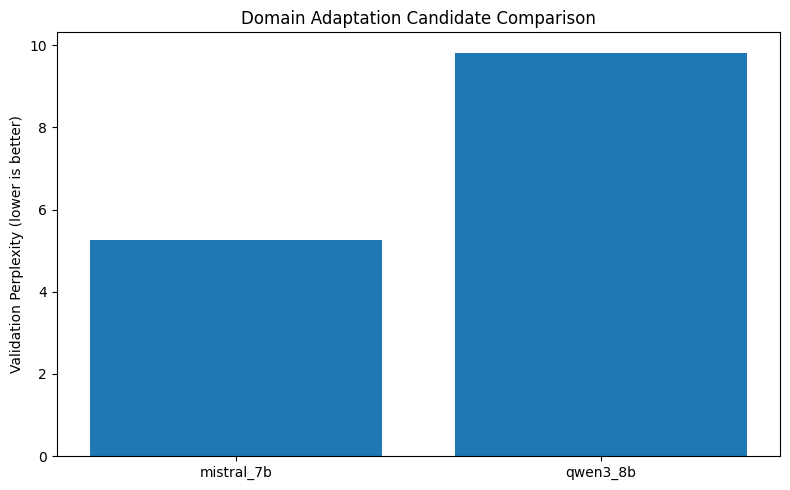

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(comparison['model_key'], comparison['validation_perplexity'])
plt.ylabel('Validation Perplexity (lower is better)')
plt.title('Domain Adaptation Candidate Comparison')
plt.tight_layout()
plt.show()

## 9. Select Checkpoint 1

For this DAPT experiment, the provisional selection criterion is lowest validation perplexity. Later, Notebook 4 should validate the choice using the independent financial benchmark suite.

In [15]:
selected = comparison.iloc[0]

checkpoint_1 = {
    'checkpoint': 'checkpoint_1',
    'model_key': selected['model_key'],
    'base_model': selected['base_model'],
    'adapter_path': selected['adapter_path'],
    'validation_perplexity': float(selected['validation_perplexity']),
    'selection_method': 'lowest validation perplexity on held-out DAPT corpus',
    'note': 'Provisional selection; confirm with independent financial benchmark evaluation.'
}

manifest_path = WORK_DIR / 'checkpoint_1_manifest.json'
manifest_path.write_text(json.dumps(checkpoint_1, indent=2))
print(json.dumps(checkpoint_1, indent=2))

{
  "checkpoint": "checkpoint_1",
  "model_key": "mistral_7b",
  "base_model": "mistralai/Mistral-7B-v0.3",
  "adapter_path": "/content/finsight_dapt/models/mistral_7b/checkpoint_1_adapter",
  "validation_perplexity": 5.270730562705297,
  "selection_method": "lowest validation perplexity on held-out DAPT corpus",
  "note": "Provisional selection; confirm with independent financial benchmark evaluation."
}


## 10. Optional: push the adapter to Hugging Face

Do this only after the experiment is complete and you have decided what you want to publish.

In [16]:
# Example:
# from huggingface_hub import login
# login()
# model.push_to_hub('YOUR_USERNAME/finsight-financial-dapt-checkpoint-1')
# tokenizer.push_to_hub('YOUR_USERNAME/finsight-financial-dapt-checkpoint-1')

In [17]:
import shutil
from google.colab import files

shutil.make_archive('finsight_dapt', 'zip', '/content/finsight_dapt')

# 2. Download the zip file to your local computer
files.download('finsight_dapt.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notebook 2 Outputs

```text
/content/finsight_dapt/
├── models/
│   ├── mistral_7b/
│   │   └── checkpoint_1_adapter/
│   └── qwen3_8b/
│       └── checkpoint_1_adapter/
├── results/
└── checkpoint_1_manifest.json
```

**Checkpoint 1 is stored as a LoRA adapter.** This is intentional: it is much smaller than saving a complete copy of an 8B model and can be loaded on top of the same base model in Notebook 3.

Record the final model, training loss, validation loss, perplexity, GPU, and training time in your project README.